# Air Quality Index (AQI) Analysis of Delhi — January 2023

**ShadowFox Data Science Internship · Intermediate Task 1**

## 1. Objective
Conduct an in-depth analysis of Delhi's air quality: identify which pollutants drive the AQI, how air quality varies over time, and which sources the data point to, using statistical tests and visualizations that can inform air-quality and public-health strategies.

## 2. Dataset
`delhiaqi.csv` — **561 hourly records, 1 Jan 2023 00:00 to 24 Jan 2023 08:00**, one monitoring series (no station/location column), 8 pollutants in µg/m³: CO, NO, NO₂, O₃, SO₂, PM2.5, PM10, NH₃. No missing values and no duplicate timestamps.

## 3. Workflow (follows the 5-step AQI guide in the task overview)
1. Collect and inspect data → 2. Clean and pre-process → 3. Compute the AQI with the official CPCB method → 4. Visualize → 5. Compare against standards (NAAQS and WHO).

## 4. Research questions
- **RQ1 – Key pollutants:** Which pollutants drive Delhi's AQI, and how far do they exceed the Indian (NAAQS) and WHO limits?
- **RQ2 – Temporal variation:** How does air quality vary across the day and across the month?
- **RQ3 – Sources:** What do relationships between pollutants (and weekday vs weekend) suggest about emission sources?
- **Scope note:** The task also mentions *seasonal variation* and *geographical factors*. This file covers only 24 days of one winter month and has no location or weather columns, so those two cannot be tested here (see Section 11).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figures", exist_ok=True)

POLLUTANTS = ["pm2_5", "pm10", "no2", "so2", "co", "no", "o3", "nh3"]
LABELS = {"pm2_5": "PM2.5", "pm10": "PM10", "no2": "NO\u2082", "so2": "SO\u2082",
          "co": "CO", "no": "NO", "o3": "O\u2083", "nh3": "NH\u2083"}
print("Libraries loaded.")

Libraries loaded.


## 5. Data loading and quality checks

In [2]:
df = pd.read_csv("delhiaqi.csv", parse_dates=["date"]).set_index("date").sort_index()

print("Shape:", df.shape)
print("Period:", df.index.min(), "->", df.index.max())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Missing values per column:")
print(df.isna().sum().to_string())
gaps = df.index.to_series().diff().value_counts()
print("\nTime step between rows:")
print(gaps.to_string())
display(df.head())

Shape: (561, 8)
Period: 2023-01-01 00:00:00 -> 2023-01-24 08:00:00
Duplicate timestamps: 0
Missing values per column:
co       0
no       0
no2      0
o3       0
so2      0
pm2_5    0
pm10     0
nh3      0

Time step between rows:
date
0 days 01:00:00    560
                          co     no    no2    o3    so2   pm2_5    pm10    nh3
date                                                                          
2023-01-01 00:00:00  1655.58   1.66  39.41  5.90  17.88  169.29  194.64   5.83
2023-01-01 01:00:00  1869.20   6.82  42.16  1.99  22.17  182.84  211.08   7.66
2023-01-01 02:00:00  2510.07  27.72  43.87  0.02  30.04  220.25  260.68  11.40
2023-01-01 03:00:00  3150.94  55.43  44.55  0.85  35.76  252.90  304.12  13.55
2023-01-01 04:00:00  3471.37  68.84  45.24  5.45  39.10  266.36  322.80  14.19


### Time zone check
Photochemical ozone peaks in the early afternoon local time. In the raw timestamps it peaks at 09:00, which matches **UTC**, not Delhi time. I therefore shift the index by +5:30 to IST. *This is an inference from the ozone pattern, not something the file states* — if your data provider confirms the timestamps are already IST, remove that cell and the time-of-day results will shift by 5.5 hours.

In [3]:
# The O3 evidence below suggests timestamps are UTC (O3 peaks at 09:00, not ~14:00).
# Check: hour of the day at which ozone is highest, on average
o3_peak_hour = df.groupby(df.index.hour)["o3"].mean().idxmax()
print("Hour with highest mean O3 in the raw timestamps:", o3_peak_hour)

# Photochemical O3 normally peaks early afternoon LOCAL time. A peak at 09:00 matches
# UTC, i.e. Delhi local time (IST) = UTC + 5:30. We convert and state this as an assumption.
df.index = df.index + pd.Timedelta(hours=5, minutes=30)
df.index.name = "date_ist"
df["hour"] = df.index.hour
df["day"] = df.index.date
print("Hour with highest mean O3 after +5:30 shift:", df.groupby("hour")["o3"].mean().idxmax())

Hour with highest mean O3 in the raw timestamps: 9
Hour with highest mean O3 after +5:30 shift: 14


### Descriptive statistics

In [4]:
summary = df[POLLUTANTS].describe().T[["mean", "50%", "std", "min", "max"]].round(1)
summary.index = [LABELS[i] for i in summary.index]
summary.columns = ["Mean", "Median", "Std", "Min", "Max"]
display(summary)
print("Units: ug/m3 for all pollutants (CO is also reported in ug/m3 in this file).")

         Mean  Median     Std    Min      Max
PM2.5   358.3   301.2   227.4   60.1   1310.2
PM10    421.0   340.9   271.3   69.1   1499.3
NO₂      75.3    63.8    42.5   13.4    263.2
SO₂      64.7    47.2    61.1    5.2    511.2
CO     3814.9  2590.2  3227.7  654.2  16876.2
NO       51.2    13.3    83.9    0.0    425.6
O₃       30.1    11.8    40.0    0.0    164.5
NH₃      26.4    14.8    36.6    0.6    267.5
Units: ug/m3 for all pollutants (CO is also reported in ug/m3 in this file).


## 6. Computing the AQI (CPCB method)
The dataset has no AQI column, so it is computed using the CPCB National AQI: each pollutant gets a sub-index by linear interpolation between CPCB breakpoints, and the **AQI is the highest sub-index**. PM, NO₂, SO₂ and NH₃ use 24-hour averages; CO (converted to mg/m³) and O₃ use 8-hour averages. The first 15 hours lack a full window and are excluded. The scale is capped at 500, which matters below.

In [5]:
# CPCB (India) National AQI: sub-index per pollutant by linear interpolation
# between breakpoints; overall AQI = the maximum sub-index (the "dominant pollutant").
# x = concentration breakpoints, y = sub-index at those breakpoints (0-500 scale).
BP = {
    "pm2_5": ([0, 30, 60, 90, 120, 250, 380],       [0, 50, 100, 200, 300, 400, 500]),
    "pm10":  ([0, 50, 100, 250, 350, 430, 510],     [0, 50, 100, 200, 300, 400, 500]),
    "no2":   ([0, 40, 80, 180, 280, 400, 520],      [0, 50, 100, 200, 300, 400, 500]),
    "so2":   ([0, 40, 80, 380, 800, 1600, 2000],    [0, 50, 100, 200, 300, 400, 500]),
    "co":    ([0, 1, 2, 10, 17, 34, 50],            [0, 50, 100, 200, 300, 400, 500]),  # mg/m3
    "o3":    ([0, 50, 100, 168, 208, 748, 1000],    [0, 50, 100, 200, 300, 400, 500]),
    "nh3":   ([0, 200, 400, 800, 1200, 1800, 2400], [0, 50, 100, 200, 300, 400, 500]),
}

# CPCB averaging periods: 24-h for PM10, PM2.5, NO2, SO2, NH3; 8-h for CO and O3.
avg = pd.DataFrame(index=df.index)
for p in ["pm2_5", "pm10", "no2", "so2", "nh3"]:
    avg[p] = df[p].rolling(24, min_periods=16).mean()
for p in ["co", "o3"]:
    conc = df[p] / 1000 if p == "co" else df[p]          # CO: ug/m3 -> mg/m3
    avg[p] = conc.rolling(8, min_periods=6).mean()

sub = pd.DataFrame({p: np.interp(avg[p], *BP[p]) for p in BP}, index=df.index)
sub[avg.isna().any(axis=1)] = np.nan                   # not enough history yet
df["aqi"] = sub.max(axis=1)
df["dominant"] = sub.dropna().idxmax(axis=1)

def category(a):
    if pd.isna(a): return np.nan
    for hi, name in [(50, "Good"), (100, "Satisfactory"), (200, "Moderate"),
                     (300, "Poor"), (400, "Very Poor")]:
        if a <= hi: return name
    return "Severe"
CATS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["category"] = pd.Categorical(df["aqi"].map(category), categories=CATS, ordered=True)

aq = df.dropna(subset=["aqi"]).copy()
print(f"AQI computed for {len(aq)} of {len(df)} hours (first 16 h lack a full 24-h window).")
display(aq["aqi"].describe().round(1).to_frame("AQI"))

AQI computed for 546 of 561 hours (first 16 h lack a full 24-h window).
         AQI
count  546.0
mean   446.2
std     62.3
min    305.4
25%    403.2
50%    473.6
75%    500.0
max    500.0


## 7. RQ1 — Key pollutants

Share of hours in each CPCB AQI category (%):
category
Good             0.0
Satisfactory     0.0
Moderate         0.0
Poor             0.0
Very Poor       24.9
Severe          75.1

Dominant pollutant (sets the AQI) - share of hours (%):
dominant
PM2.5    100.0


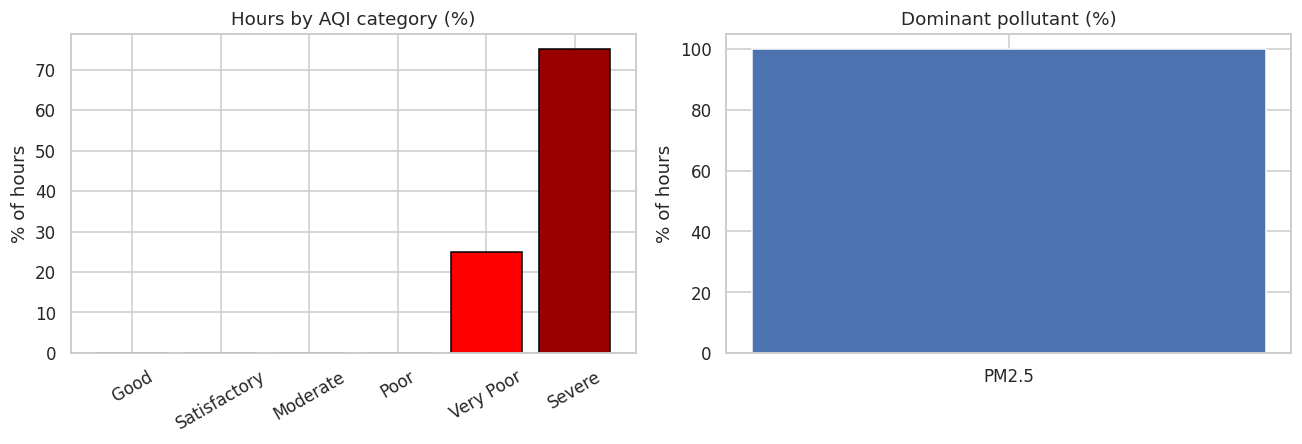

In [6]:
# RQ1 - Which pollutants drive Delhi's AQI, and how far above the standards are they?
cat_counts = aq["category"].value_counts().reindex(CATS).fillna(0).astype(int)
cat_pct = (cat_counts / cat_counts.sum() * 100).round(1)
print("Share of hours in each CPCB AQI category (%):")
print(cat_pct.to_string())

dom = aq["dominant"].value_counts()
print("\nDominant pollutant (sets the AQI) - share of hours (%):")
print((dom / dom.sum() * 100).round(1).rename(index=LABELS).to_string())

colors = ["#00b050", "#92d050", "#ffff00", "#ff9900", "#ff0000", "#990000"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(CATS, cat_pct.values, color=colors, edgecolor="black")
ax[0].set_title("Hours by AQI category (%)"); ax[0].tick_params(axis="x", rotation=30)
ax[0].set_ylabel("% of hours")
ax[1].bar([LABELS[i] for i in dom.index], dom.values / dom.sum() * 100, color="#4c72b0")
ax[1].set_title("Dominant pollutant (%)"); ax[1].set_ylabel("% of hours")
plt.tight_layout(); plt.savefig("figures/01_category_and_dominant.png", bbox_inches="tight"); plt.show()

**Findings.** Not a single hour was better than *Very Poor*: 75.1% of hours were *Severe* and 24.9% *Very Poor*. **PM2.5 set the AQI in 100% of hours.** Because the AQI is capped at 500, 75% of hours sit at the ceiling, so the AQI understates how bad the worst hours were; raw concentrations (below) are more informative.

In [7]:
# Comparison with Indian NAAQS (24-h) and WHO 2021 guideline values
NAAQS = {"pm2_5": 60, "pm10": 100, "no2": 80, "so2": 80, "nh3": 400}   # ug/m3, 24-h
WHO   = {"pm2_5": 15, "pm10": 45, "no2": 25, "so2": 40}                # ug/m3, 24-h
daily = df[POLLUTANTS].resample("D").mean()
daily = daily[df["hour"].resample("D").count() == 24]                    # complete days only

rows = []
for p, lim in NAAQS.items():
    rows.append({"Pollutant": LABELS[p], "Mean of daily means": daily[p].mean(),
                 "NAAQS 24-h": lim,
                 "Days above NAAQS (%)": (daily[p] > lim).mean() * 100,
                 "x NAAQS": daily[p].mean() / lim,
                 "x WHO": daily[p].mean() / WHO[p] if p in WHO else np.nan})
exceed = pd.DataFrame(rows).set_index("Pollutant").round(1)
print(f"Complete days analysed: {len(daily)}")
display(exceed)

co8 = (df["co"] / 1000).rolling(8).mean()
print(f"CO: share of hours with 8-h mean above 2 mg/m3 (NAAQS): {(co8 > 2).mean()*100:.1f}%")

Complete days analysed: 22
           Mean of daily means  NAAQS 24-h  Days above NAAQS (%)  x NAAQS  x WHO
Pollutant                                                                       
PM2.5                    357.6          60                 100.0      6.0   23.8
PM10                     419.4         100                 100.0      4.2    9.3
NO₂                       75.3          80                  31.8      0.9    3.0
SO₂                       64.3          80                  18.2      0.8    1.6
NH₃                       26.0         400                   0.0      0.1    NaN
CO: share of hours with 8-h mean above 2 mg/m3 (NAAQS): 74.0%


**Findings.** Mean PM2.5 was about **6× the Indian 24-h standard and 24× the WHO guideline**; PM10 was 4.2× NAAQS and 9× WHO. **Every complete day exceeded the NAAQS for both PM2.5 and PM10.** Gases were closer to their limits: NO₂ exceeded the standard on about 32% of days (about 3× the WHO guideline on average), SO₂ on about 18% of days, and NH₃ never. CO's 8-hour mean was above 2 mg/m³ in 74% of hours.

PM2.5/PM10 ratio: mean 0.85, median 0.86


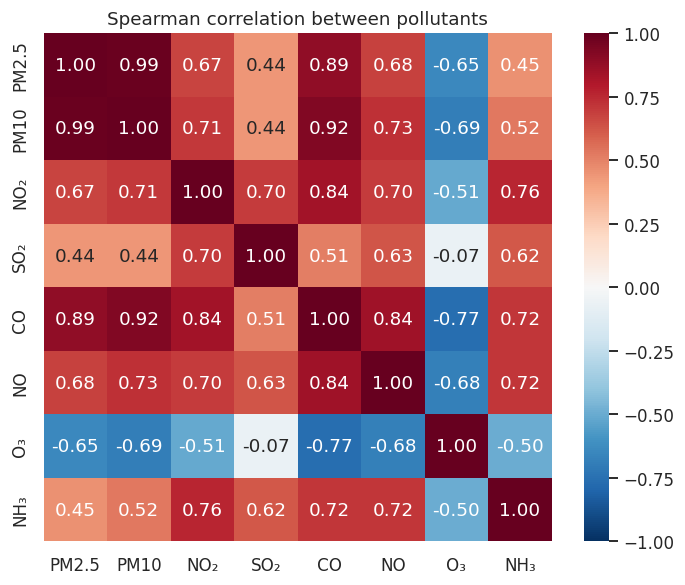

In [8]:
# How are the pollutants related? (Spearman: robust to the heavy right-skew in the data)
corr = df[POLLUTANTS].corr(method="spearman")
corr.index = corr.columns = [LABELS[c] for c in corr.columns]
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation between pollutants")
plt.savefig("figures/02_correlation_heatmap.png", bbox_inches="tight"); plt.show()

ratio = (df["pm2_5"] / df["pm10"])
print(f"PM2.5/PM10 ratio: mean {ratio.mean():.2f}, median {ratio.median():.2f}")

**Findings.** PM2.5 and PM10 are almost perfectly correlated (ρ = 0.99) and PM2.5 is about 85% of PM10, so the pollution is dominated by **fine particles** typical of combustion and secondary formation rather than coarse road or construction dust. Particulates track CO (PM2.5–CO ρ = 0.89) and NO₂ (ρ = 0.67), consistent with shared combustion sources. O₃ is negatively correlated with almost everything: it is consumed where fresh emissions are high (see RQ3).

## 8. RQ2 — Temporal variation

Best and worst days (complete days only):
            Mean AQI  Max AQI
date_ist                     
2023-01-16     322.0    341.0
2023-01-15     348.0    463.0
2023-01-17     348.0    379.0
2023-01-02     500.0    500.0
2023-01-03     500.0    500.0
2023-01-06     500.0    500.0
Days with a mean AQI in Severe (>400): 16 of 22


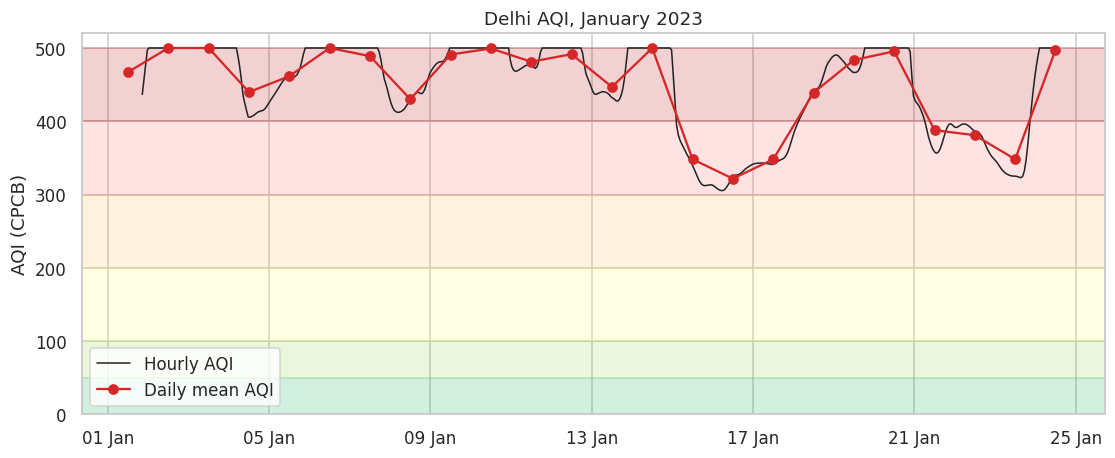

In [9]:
# RQ2 - How does air quality vary over time (day to day, and within the day)?
fig, ax = plt.subplots(figsize=(12, 4.5))
bands = [(0, 50, "#00b050"), (50, 100, "#92d050"), (100, 200, "#ffff66"),
         (200, 300, "#ffb84d"), (300, 400, "#ff6666"), (400, 500, "#b30000")]
for lo, hi, c in bands:
    ax.axhspan(lo, hi, color=c, alpha=0.18)
ax.plot(aq.index, aq["aqi"], lw=1, color="#222", label="Hourly AQI")
ax.plot(aq["aqi"].resample("D").mean().index + pd.Timedelta(hours=12),
        aq["aqi"].resample("D").mean().values, "o-", color="#d62728", label="Daily mean AQI")
ax.set_ylim(0, 520); ax.set_ylabel("AQI (CPCB)"); ax.set_title("Delhi AQI, January 2023")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(loc="lower left")
plt.savefig("figures/03_aqi_timeline.png", bbox_inches="tight"); plt.show()

d_aqi = aq["aqi"].resample("D").agg(["mean", "max", "count"]).round(0)
d_aqi = d_aqi[d_aqi["count"] == 24].drop(columns="count")
d_aqi.columns = ["Mean AQI", "Max AQI"]
print("Best and worst days (complete days only):")
display(pd.concat([d_aqi.nsmallest(3, "Mean AQI"), d_aqi.nlargest(3, "Mean AQI")]))
print("Days with a mean AQI in Severe (>400):", int((d_aqi["Mean AQI"] > 400).sum()), "of", len(d_aqi))

**Findings.** Of 22 complete days, **16 had a daily-mean AQI in the Severe range; no day was better than Very Poor.** The cleanest days were 15–17 Jan (mean AQI about 320–350, still Very Poor); the worst (e.g. 2, 3 and 6 Jan) reached the 500 cap. Mean AQI declined over the month (Spearman ρ = −0.44, p < 0.001), but with 24 days this cannot be separated from weather changes.

Hour (IST) of peak mean PM2.5: 22 -> 540 ug/m3
Hour (IST) of lowest mean PM2.5: 13 -> 194 ug/m3


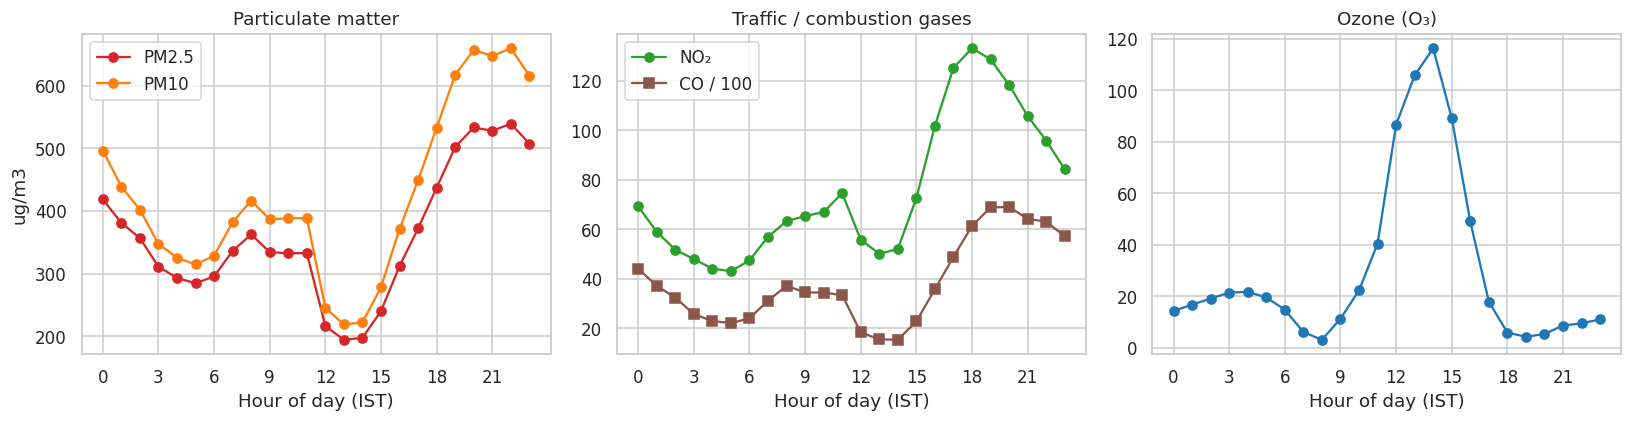

In [10]:
# Diurnal (time-of-day) pattern in local time (IST)
hourly = df.groupby("hour")[["pm2_5", "pm10", "no2", "co", "o3"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for p, c in [("pm2_5", "#d62728"), ("pm10", "#ff7f0e")]:
    axes[0].plot(hourly.index, hourly[p], marker="o", color=c, label=LABELS[p])
axes[0].set_title("Particulate matter"); axes[0].set_ylabel("ug/m3"); axes[0].legend()
axes[1].plot(hourly.index, hourly["no2"], marker="o", color="#2ca02c", label="NO\u2082")
axes[1].plot(hourly.index, hourly["co"] / 100, marker="s", color="#8c564b", label="CO / 100")
axes[1].set_title("Traffic / combustion gases"); axes[1].legend()
axes[2].plot(hourly.index, hourly["o3"], marker="o", color="#1f77b4")
axes[2].set_title("Ozone (O\u2083)")
for a in axes:
    a.set_xlabel("Hour of day (IST)"); a.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.savefig("figures/04_diurnal_profile.png", bbox_inches="tight"); plt.show()

print("Hour (IST) of peak mean PM2.5:", hourly["pm2_5"].idxmax(), "->", round(hourly["pm2_5"].max()), "ug/m3")
print("Hour (IST) of lowest mean PM2.5:", hourly["pm2_5"].idxmin(), "->", round(hourly["pm2_5"].min()), "ug/m3")

**Findings.** PM, CO and NO₂ follow a clear daily cycle: **lowest around 13:00 IST (mean PM2.5 ≈ 194 µg/m³) and highest in the late evening around 22:00 (≈ 540 µg/m³)**. The afternoon dip coincides with the ozone peak, when the atmosphere is typically better mixed and sunlight is strongest. The evening build-up fits rush-hour emissions released into a shallower night-time layer — an interpretation from general atmospheric science, since this dataset has no meteorological data to confirm it.

                    mean  median
part                            
Morning (05-11)    324.0   294.0
Afternoon (11-17)  249.0   235.0
Evening (17-22)    475.0   382.0
Night (22-05)      401.0   323.0

Kruskal-Wallis (PM2.5 differs across parts of day): H = 69.7, p = 4.91e-15
AQI vs time (trend over the month): rho = -0.44, p = 0.000


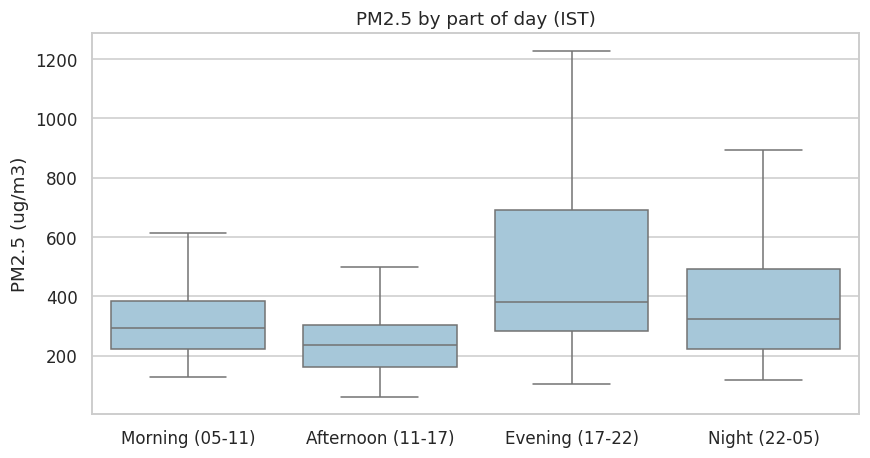

In [11]:
# Statistical tests on time-of-day effects (non-parametric: data are skewed)
def part_of_day(h):
    return ("Night (22-05)" if h >= 22 or h < 5 else "Morning (05-11)" if h < 11
            else "Afternoon (11-17)" if h < 17 else "Evening (17-22)")
df["part"] = df["hour"].map(part_of_day)
order = ["Morning (05-11)", "Afternoon (11-17)", "Evening (17-22)", "Night (22-05)"]

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="part", y="pm2_5", order=order, color="#9ecae1", showfliers=False)
plt.title("PM2.5 by part of day (IST)"); plt.xlabel(""); plt.ylabel("PM2.5 (ug/m3)")
plt.savefig("figures/05_pm25_by_part_of_day.png", bbox_inches="tight"); plt.show()

print(df.groupby("part")["pm2_5"].agg(["mean", "median"]).reindex(order).round(0).to_string())
groups = [df.loc[df["part"] == o, "pm2_5"] for o in order]
H, p = stats.kruskal(*groups)
print(f"\nKruskal-Wallis (PM2.5 differs across parts of day): H = {H:.1f}, p = {p:.2e}")

# Is there a trend across the 24 days?  (Spearman of AQI vs time)
t = (aq.index - aq.index[0]).total_seconds() / 86400
rho, p = stats.spearmanr(t, aq["aqi"])
print(f"AQI vs time (trend over the month): rho = {rho:.2f}, p = {p:.3f}")

**Findings.** PM2.5 differs significantly across parts of the day (Kruskal-Wallis H = 69.7, p < 10⁻¹⁴): mean **475 µg/m³ in the evening, 401 at night, 324 in the morning and 249 in the afternoon**. Even the cleanest period is about 4× the NAAQS 24-h limit.

## 9. RQ3 — Source signatures

Spearman PM2.5 vs CO  : rho = +0.89  (p = 2.3e-191)
Spearman PM2.5 vs NO₂ : rho = +0.67  (p = 1.1e-75)
Spearman    O₃ vs NO  : rho = -0.68  (p = 9.4e-78)
Spearman   SO₂ vs NO₂ : rho = +0.70  (p = 8.4e-83)


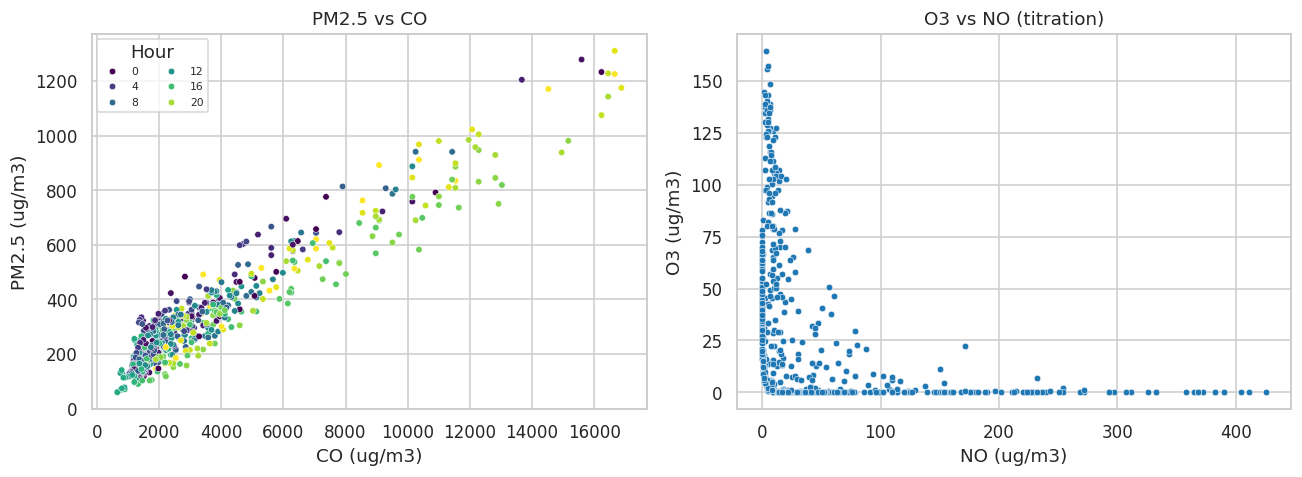

In [12]:
# Source signatures: traffic/combustion tracers (CO, NO, NO2) vs ozone
# NO + O3 -> NO2 (titration) makes ozone fall when fresh emissions are high.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=df, x="co", y="pm2_5", hue="hour", palette="viridis", s=18, ax=ax[0])
ax[0].set_xlabel("CO (ug/m3)"); ax[0].set_ylabel("PM2.5 (ug/m3)"); ax[0].set_title("PM2.5 vs CO")
ax[0].legend(title="Hour", ncol=2, fontsize=7)
sns.scatterplot(data=df, x="no", y="o3", color="#1f77b4", s=18, ax=ax[1])
ax[1].set_xlabel("NO (ug/m3)"); ax[1].set_ylabel("O3 (ug/m3)"); ax[1].set_title("O3 vs NO (titration)")
plt.tight_layout(); plt.savefig("figures/06_source_signatures.png", bbox_inches="tight"); plt.show()

for a, b in [("pm2_5", "co"), ("pm2_5", "no2"), ("o3", "no"), ("so2", "no2")]:
    r, p = stats.spearmanr(df[a], df[b])
    print(f"Spearman {LABELS[a]:>5} vs {LABELS[b]:<4}: rho = {r:+.2f}  (p = {p:.1e})")

**Findings.** PM2.5 rises with CO (ρ = +0.89) and NO₂ (ρ = +0.67), and SO₂ moves with NO₂ (ρ = +0.70), which points to combustion-related sources (vehicles, and likely fuel burning) rather than a single dominant source. O₃ falls as NO rises (ρ = −0.68), the classic NO + O₃ → NO₂ titration signature of fresh, nearby traffic/combustion emissions. These are associations; the data cannot attribute pollution to specific sources.

In [13]:
# Weekday vs weekend (Jan 2023: weekend days are 1, 7, 8, 14, 15, 21, 22)
df["weekend"] = df.index.dayofweek >= 5
d = df.resample("D")[["pm2_5", "no2", "co"]].mean()
d = d[df["hour"].resample("D").count() == 24]
d["weekend"] = d.index.dayofweek >= 5
print(d.groupby("weekend")[["pm2_5", "no2", "co"]].mean().round(0)
      .rename(index={False: "Weekday", True: "Weekend"}).to_string())
print("Number of daily observations:", d.groupby("weekend").size().rename({False: "Weekday", True: "Weekend"}).to_dict())
for p in ["pm2_5", "no2", "co"]:
    u, pv = stats.mannwhitneyu(d.loc[d.weekend, p], d.loc[~d.weekend, p])
    print(f"Mann-Whitney {LABELS[p]:>5}: p = {pv:.2f}")

         pm2_5   no2      co
weekend                     
Weekday  394.0  83.0  4299.0
Weekend  261.0  54.0  2413.0
Number of daily observations: {'Weekday': 16, 'Weekend': 6}
Mann-Whitney PM2.5: p = 0.04
Mann-Whitney   NO₂: p = 0.00
Mann-Whitney    CO: p = 0.01


**Findings.** Weekdays were worse than weekends: mean PM2.5 **394 vs 261 µg/m³**, NO₂ 83 vs 54 µg/m³, CO 4,299 vs 2,413 µg/m³ (Mann-Whitney p = 0.04 for PM2.5, < 0.01 for NO₂, 0.01 for CO). **Caution:** this compares only 16 weekdays with 6 weekend days in a single month, and weather can differ between those days. Treat it as a hint that activity-linked sources matter, not as proof.

## 10. Key findings and recommendations

**Key findings**
1. Air quality was *Very Poor* or *Severe* for the entire record; **PM2.5 was the controlling pollutant in every hour**, at roughly 6× the Indian standard.
2. Fine particles dominate (PM2.5 ≈ 85% of PM10) and move with CO and NO₂, pointing to combustion sources.
3. A strong daily cycle: **worst ~17:00–05:00 (peak ~22:00), best ~11:00–17:00 (trough ~13:00)**.
4. Weekdays were more polluted than weekends, suggesting activity-linked emissions (suggestive only; small sample).
5. NH₃ and, mostly, SO₂ stayed within limits; **particulates are the problem to tackle first**, with NO₂ and CO as secondary targets.

**Recommendations for air-quality and public-health strategy** (these follow from the patterns above; they are suggestions, not tested interventions)
- **Prioritise PM2.5 reduction** and the combustion sources behind it (vehicle exhaust, fuel and waste burning), since PM2.5 drove the AQI in all hours.
- **Target evening and night emissions**: enforce rules on open burning and heavy-vehicle movement in the 17:00–05:00 window when concentrations peak.
- **Time public-health advisories**: advise limiting outdoor exercise in the evening and at night; the early-afternoon window is relatively cleaner, but it is still above the Indian standard, so it is not "safe".
- **Protect vulnerable groups** (children, elderly, people with respiratory/heart disease) with masks, indoor air filtration and school advisories during Severe days.
- **Strengthen monitoring**: add multi-station and meteorological data (wind, temperature, humidity, mixing height) to move from description to explanation.

## 11. Limitations and what this analysis could not test
- **Seasonal variation:** only 24 days of January (winter) are available, so seasons cannot be compared. With a multi-year file, group by month or season and apply a Kruskal-Wallis test, as done here for time of day.
- **Geographical factors:** there is no station, coordinates or wind data, so spatial differences and transport from outside Delhi cannot be assessed. Delhi's winter conditions (cool, calm air that traps pollutants, and regional crop-residue burning in the autumn) are often cited in the literature, but **nothing in this dataset tests them**.
- **Time zone:** the UTC→IST conversion is inferred (Section 5).
- **AQI cap:** 75% of hours sit at the 500 ceiling, which compresses variation in the AQI itself.
- **Significance tests** assume independent observations, but hourly data are autocorrelated, so p-values are optimistic; effect sizes and plots matter more than the exact p-values.

## 12. Reproducibility
Run all cells top to bottom with `delhiaqi.csv` in the same folder. Requires `pandas numpy matplotlib seaborn scipy`. Figures are saved to `figures/`, and the computed AQI table to `delhi_aqi_hourly_with_cpcb_aqi.csv`.

In [14]:
# Save the computed hourly AQI table for reuse (e.g. in the GitHub repo)
out = df[POLLUTANTS + ["aqi", "dominant", "category"]].copy()
out.to_csv("delhi_aqi_hourly_with_cpcb_aqi.csv")
print("Saved delhi_aqi_hourly_with_cpcb_aqi.csv", out.shape)

Saved delhi_aqi_hourly_with_cpcb_aqi.csv (561, 11)
